# 03 – Baseline models: Logistic regression, Random forest, LightGBM

**Đầu vào:** `data/processed/telco_clean.csv`, `data/processed/splits.csv` (từ notebook 02)
**Đầu ra:**
- `model_output/models/{lr,rf,lgbm}.joblib`: pipeline (fit trên train) + calibrator (fit trên val)
- `model_output/tables/`: kết quả chọn feature, CV, calibration, so sánh mô hình, phân tích ngưỡng
- `model_output/tables/val_predictions.csv`: `p_churn` của từng khách trong val, dùng cho simulator chạy thử
- `model_output/figures/m01–m04`

Toàn bộ logic nằm trong [`src/modeling.py`](../src/modeling.py), tham số trong [`src/config.yaml`](../src/config.yaml) (mục `models`, `calibration`, `threshold_analysis`).

| Làm trong notebook này | Để dành cho bước sau |
|---|---|
| 1. Khung bài toán, kiểm tra leakage | Value proxy, công thức EV, simulator targeting |
| 2. Chọn feature cho LR | Chọn mô hình chính theo giá trị ròng (EV) trên val |
| 3. Tuning 3 mô hình bằng CV trên train | Đánh giá cuối trên test (**một lần**) |
| 4. Calibration trên val | SHAP / feature attribution (stretch) |
| 5. So sánh mô hình trên val | |
| 6. Phân tích ngưỡng | |

> **Tập test bị khoá trong notebook này.** Notebook chỉ giữ train và val. Test chỉ được dùng một lần, sau khi đã chốt mô hình và chính sách targeting.

## 0. Setup

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import precision_recall_curve, roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

from src import preprocessing as pp
from src import modeling as md

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

config = pp.load_config()
{k: config[k] for k in ["random_state", "models", "calibration", "threshold_analysis"]}

{'random_state': 42,
 'models': {'cv_folds': 5,
  'refit_metric': 'neg_log_loss',
  'lr': {'grid': {'C': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]}},
  'rf': {'params': {'n_estimators': 500},
   'grid': {'max_features': [0.1, 'sqrt', 0.3, 0.5],
    'min_samples_leaf': [5, 10, 20, 40],
    'max_depth': [None, 10]}},
  'lgbm': {'params': {'learning_rate': 0.03,
    'subsample': 0.8,
    'subsample_freq': 1,
    'colsample_bytree': 0.8},
   'grid': {'n_estimators': [200, 400, 800, 1600],
    'num_leaves': [2, 3, 4, 8],
    'min_child_samples': [50, 100, 200, 400],
    'reg_lambda': [0, 5]}}},
 'calibration': {'methods': ['none', 'sigmoid', 'isotonic'],
  'cv_folds': 5,
  'n_bins': 10},
 'threshold_analysis': {'thresholds': [0.2, 0.3, 0.4, 0.5, 0.6],
  'top_k_shares': [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5],
  'n_bootstrap': 1000}}

In [2]:
# Chart style matches notebooks 01–02. Model colours follow the fixed categorical order: LR → RF → LightGBM
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
MODEL_COLORS = {"lr": BLUE, "rf": ORANGE, "lgbm": AQUA}
LABELS = md.MODEL_LABELS
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
OUT_DIR = ROOT / "model_output"
FIG_DIR, TAB_DIR, MODEL_DIR = OUT_DIR / "figures", OUT_DIR / "tables", OUT_DIR / "models"
for d in (FIG_DIR, TAB_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [3]:
data = pp.load_processed(config)
train = data[data["split"] == "train"].drop(columns="split").reset_index(drop=True)
val = data[data["split"] == "val"].drop(columns="split").reset_index(drop=True)
n_test = int(data["split"].eq("test").sum())
del data   # test is not kept in this notebook
y_tr, y_val = train[pp.TARGET].to_numpy(), val[pp.TARGET].to_numpy()

display(pd.DataFrame(
    {"n": [len(train), len(val), n_test], "churn": [y_tr.sum(), y_val.sum(), np.nan],
     "churn_rate": [y_tr.mean(), y_val.mean(), np.nan]},
    index=["train", "val", "test (locked)"],
).style.format({"n": "{:,}", "churn": "{:,.0f}", "churn_rate": "{:.2%}"}, na_rep="—"))

,n,churn,churn_rate
train,"4,225","1,121",26.53%
val,"1,409",374,26.54%
test (locked),"1,409",—,—


## 1. Khung bài toán và kiểm tra leakage

| | |
|---|---|
| **Quyết định** | Với ngân sách giữ chân có hạn, khách nào nên nhận ưu đãi |
| **Đơn vị phân tích** | Một khách hàng (`customerID`) tại thời điểm snapshot |
| **Biến mục tiêu** | `y = 1` nếu khách rời mạng (cột `Churn` gốc: rời đi trong tháng gần nhất), coi là kết quả của kỳ tiếp theo |
| **Thời điểm ra quyết định** | Tại snapshot, trước khi khách rời đi |
| **Đầu ra của mô hình** | `p_churn` đã kiểm tra calibration, là đầu vào của công thức EV ở bước sau. Vì vậy chọn tham số theo **log loss**, không theo accuracy hay AUC |
| **Thiết kế kiểm định** | Dữ liệu là một snapshot, không có mốc thời gian, nên chia ngẫu nhiên stratified 60/20/20 (notebook 02). Không làm được temporal holdout: đây là một giới hạn cần ghi vào model card |
| **Train** | Tuning bằng 5-fold stratified CV |
| **Val** | Calibration, so sánh mô hình, phân tích ngưỡng |

**Leakage.** Mọi feature mô tả tài khoản của khách tại snapshot: nhân khẩu học, dịch vụ, hợp đồng, thanh toán, tenure, cước. Bản dữ liệu này **không có** các cột chỉ biết sau khi khách rời đi (`Churn Reason`, `Churn Score`, `CLTV` chỉ có trong bản IBM mở rộng). Rủi ro còn lại: `tenure` và `TotalCharges` của khách churn được ghi cùng snapshot với nhãn, nên có thể đã gồm tháng cuối. Rủi ro này nhỏ và được ghi vào phần giới hạn.

**Không dùng `gender`** cho mô hình nào: không có tín hiệu (p = 0.49 trong EDA) và có rủi ro fairness.

In [4]:
def feature_list(f):
    return [*f["num_cols"], *f["cat_cols"], *f["bin_cols"]]


FEATURE_SETS = {"LR (base)": feature_list(md.LR_FEATURES), "LR (candidates)": md.LR_CANDIDATES,
                "RF / LightGBM": feature_list(md.TREE_FEATURES)}
all_cols = list(dict.fromkeys(c for cols in FEATURE_SETS.values() for c in cols))
feature_table = pd.DataFrame({name: ["✓" if c in cols else "" for c in all_cols] for name, cols in FEATURE_SETS.items()},
                             index=pd.Index(all_cols, name="feature"))
display(feature_table)

POST_OUTCOME = {"Churn", "Churn Reason", "Churn Score", "Churn Label", "Churn Value", "CLTV"}
used = set(all_cols)
checks = {
    "Data has no post-outcome columns (Churn Reason / Score / CLTV…)": not POST_OUTCOME & set(train.columns),
    "No model uses the label y": pp.TARGET not in used,
    "No model uses customerID": pp.ID_COL not in used,
    "No model uses gender": "gender" not in used,
    "All features exist in the data (except modelling-step features)": used - {"abs_charge_change"} <= set(train.columns),
}
display(pd.Series(checks, name="Passed").to_frame())
assert all(checks.values())

,LR (base),LR (candidates),RF / LightGBM
feature,,,
tenure,✓,,✓
Contract,✓,,✓
InternetService,✓,,✓
PaymentMethod,✓,,✓
monthly_charge_band,✓,,
SeniorCitizen,✓,,✓
Partner,✓,,✓
Dependents,✓,,✓
PhoneService,✓,,✓


,Passed
Data has no post-outcome columns (Churn Reason / Score / CLTV…),True
No model uses the label y,True
No model uses customerID,True
No model uses gender,True
All features exist in the data (except modelling-step features),True


## 2. Chọn feature cho logistic regression

**Bộ gốc** theo ghi chú chuyển tiếp của preprocessing ([`docs/eda_to_preprocessing.md`](../docs/eda_to_preprocessing.md) mục 4.6 và 7):
- `tenure` dạng số; `MonthlyCharges` dùng dạng `monthly_charge_band`.
- Biến gốc của dịch vụ, hợp đồng, thanh toán; hai biến tương tác `m2m_fiber`, `m2m_echeck`.
- **Không** dùng `num_addons` (tổng đúng của 6 cột add-on), `auto_payment` (tổng của 2 dummy `PaymentMethod`), `has_protection` / `has_streaming` (max của biến gốc), `is_new_customer` (cờ nghiệp vụ, trùng `tenure`), `avg_past_charge` (r = 0.996 với `MonthlyCharges`). Hai biến đầu gây **đa cộng tuyến hoàn toàn** nếu dùng cùng biến gốc.

**Hai biến số ứng viên**, mỗi biến chỉ giữ nếu cải thiện CV log loss:
- `log_TotalCharges`: lịch sử cước tích luỹ. Tương quan 0.83 với `tenure`.
- `abs_charge_change` = |`charge_change`|: cho tín hiệu hình chữ V (cả tăng và giảm cước đều gắn với churn cao, preprocessing mục 4.4).

**Quy tắc chọn:** mỗi biến thể được tune `C` riêng. Mọi biến thể dùng **cùng các fold CV**, nên so sánh ghép cặp theo fold. Chọn biến thể có CV log loss thấp nhất, nhưng chỉ khi nó tốt hơn bộ gốc quá 1 SE của chênh lệch ghép cặp; nếu không thì giữ bộ gốc (bộ đơn giản hơn).

In [5]:
def fold_log_loss(search):
    i = search.best_index_
    return -np.array([search.cv_results_[f"split{f}_test_neg_log_loss"][i] for f in range(search.n_splits_)])


variants = {"base": [], **{f"+ {c}": [c] for c in md.LR_CANDIDATES}, "+ both": md.LR_CANDIDATES}
lr_searches = {v: md.tune("lr", train, config, md.with_numeric(md.LR_FEATURES, extra)) for v, extra in variants.items()}
base_folds = fold_log_loss(lr_searches["base"])

rows = []
for v, s in lr_searches.items():
    cv = md.cv_summary(s)
    diff = fold_log_loss(s) - base_folds
    rows.append({"variant": v, "C": s.best_params_["clf__C"], "CV log loss": cv["log_loss"],
                 "CV ROC-AUC": cv["roc_auc"], "CV PR-AUC": cv["average_precision"],
                 "Δ log loss vs base": diff.mean(), "SE(Δ)": diff.std(ddof=1) / np.sqrt(len(diff)),
                 "folds better": int((diff < 0).sum())})
lr_select = pd.DataFrame(rows).set_index("variant")
lr_select.to_csv(TAB_DIR / "lr_feature_selection.csv")

best = lr_select["CV log loss"].idxmin()
chosen = best if lr_select.loc[best, "Δ log loss vs base"] < -lr_select.loc[best, "SE(Δ)"] else "base"
LR_FINAL = md.with_numeric(md.LR_FEATURES, variants[chosen])

display(lr_select.style.format({"C": "{:g}", "CV log loss": "{:.4f}", "CV ROC-AUC": "{:.4f}", "CV PR-AUC": "{:.4f}",
                                "Δ log loss vs base": "{:+.4f}", "SE(Δ)": "{:.4f}"}))
print(f"Selected: {chosen!r} → LR numeric features: {LR_FINAL['num_cols']}")

,C,CV log loss,CV ROC-AUC,CV PR-AUC,Δ log loss vs base,SE(Δ),folds better
variant,,,,,,,
base,1,0.4152,0.8470,0.6622,+0.0000,0.0000,0
+ log_TotalCharges,1,0.4081,0.8521,0.6787,-0.0071,0.0010,5
+ abs_charge_change,0.3,0.4142,0.8476,0.6659,-0.0010,0.0017,3
+ both,1,0.4085,0.8518,0.6777,-0.0067,0.0007,5


Selected: '+ log_TotalCharges' → LR numeric features: ['tenure', 'log_TotalCharges']


### 2.1 Đa cộng tuyến của bộ feature LR cuối cùng
VIF tính trên train sau khi encode (`drop_first=True`) và scale. Ngưỡng hay dùng: VIF > 5 đáng chú ý, VIF > 10 là nghiêm trọng.

In [6]:
X_lr = pp.build_preprocessor(**LR_FINAL, scale=True, drop_first=True).fit_transform(md.add_model_features(train))
X_vif = np.column_stack([np.ones(len(X_lr)), X_lr.to_numpy(dtype=float)])
vif = pd.Series([variance_inflation_factor(X_vif, i + 1) for i in range(X_lr.shape[1])],
                index=X_lr.columns, name="VIF").sort_values(ascending=False)
print(f"{X_lr.shape[1]} columns after encoding; VIF > 5: {(vif > 5).sum()} columns; VIF > 10: {(vif > 10).sum()} columns")
display(vif.head(10).round(2).to_frame())

26 columns after encoding; VIF > 5: 9 columns; VIF > 10: 0 columns


,VIF
InternetService_No,8.32
tenure,6.84
InternetService_Fiber optic,6.83
log_TotalCharges,6.63
monthly_charge_band_>100,6.59
monthly_charge_band_<=25,6.44
monthly_charge_band_70-100,5.72
m2m_echeck,5.13
m2m_fiber,5.00
PaymentMethod_Electronic check,4.64


**Kết quả chọn feature cho LR**
- **`log_TotalCharges`: giữ.** CV log loss giảm 0.0071 (SE 0.0010), tốt hơn ở cả 5/5 fold. ROC-AUC tăng từ 0.847 lên 0.852, PR-AUC từ 0.662 lên 0.679. Với cùng `tenure`, khách đã trả tổng cộng nhiều hơn thì ít churn hơn. Biến này mang phần thông tin về lịch sử cước mà `tenure` và `monthly_charge_band` chưa có.
- **`abs_charge_change`: bỏ.** Chỉ cải thiện 0.0010 (SE 0.0017, 3/5 fold). Dùng kèm `log_TotalCharges` còn kém hơn dùng riêng `log_TotalCharges`. Tín hiệu chữ V của `charge_change` phần lớn đã nằm trong `tenure` (điểm 0 là khách tenure ≤ 1) và `log_TotalCharges`.
- **VIF** lớn nhất là 8.3 (`InternetService_No`); không cột nào vượt 10. 9 cột có VIF từ 5 đến 8.3, chủ yếu do các liên hệ có tính cấu trúc:
  - `tenure` với `log_TotalCharges`
  - `InternetService` với `monthly_charge_band` (cước gần như do gói dịch vụ quyết định)
  - `m2m_*` với các biến gốc của chúng

  Mức này chấp nhận được cho mục tiêu dự đoán vì mô hình có L2. Tuy vậy, **không diễn giải riêng lẻ** hệ số của các cột này.

## 3. Tuning bằng cross-validation trên train

| Mô hình | Encoding | Lưới tham số (`config.yaml`) |
|---|---|---|
| Logistic regression | Scale + one-hot `drop_first` | `C` (L2) |
| Random forest | Dạng gốc, one-hot đủ mức | `max_features`, `min_samples_leaf`, `max_depth`; 500 cây |
| LightGBM | Dạng gốc, one-hot đủ mức | `n_estimators`, `num_leaves`, `min_child_samples`, `reg_lambda`; `learning_rate` = 0.03, subsample 0.8 |

- Cả ba dùng **cùng 5 fold** stratified, chọn tham số theo **log loss**. Ghi thêm ROC-AUC, PR-AUC, Brier.
- Không dùng `class_weight` hay resample: cả hai làm lệch xác suất (notebook 02, mục 6.2).
- Encoding / scaling nằm trong pipeline nên được fit lại trong từng fold.

In [7]:
FEATURES = {"lr": LR_FINAL, "rf": md.TREE_FEATURES, "lgbm": md.TREE_FEATURES}
searches, fit_time = {}, {}
for name in md.MODELS:
    t0 = time.perf_counter()
    searches[name] = md.tune(name, train, config, FEATURES[name])
    fit_time[name] = time.perf_counter() - t0


def mean_se(mean, se, fmt="{:.4f}"):
    return f"{fmt.format(mean)} ± {fmt.format(se)}"


cv_rows = []
for n, s in searches.items():
    cv = md.cv_summary(s)
    cv_rows.append({"model": LABELS[n], "n_combinations": len(s.cv_results_["params"]), "time (s)": round(fit_time[n], 1),
                    **{m: mean_se(cv[k], cv[f"{k}_se"]) for m, k in
                       [("log loss", "log_loss"), ("ROC-AUC", "roc_auc"), ("PR-AUC", "average_precision"), ("Brier", "brier_score")]}})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.to_csv(TAB_DIR / "cv_results.csv")
display(cv_table)

,n_combinations,time (s),log loss,ROC-AUC,PR-AUC,Brier
model,,,,,,
Logistic regression,10,0.2,0.4081 ± 0.0069,0.8521 ± 0.0056,0.6787 ± 0.0086,0.1322 ± 0.0022
Random forest,32,21.8,0.4140 ± 0.0062,0.8482 ± 0.0058,0.6663 ± 0.0085,0.1345 ± 0.0020
LightGBM,128,12.2,0.4090 ± 0.0064,0.8514 ± 0.0056,0.6757 ± 0.0075,0.1328 ± 0.0022


### 3.1 Tham số tốt nhất và kiểm tra biên lưới
Nếu tham số tốt nhất nằm ở **biên** của một lưới có từ 3 giá trị trở lên, giá trị tối ưu thật có thể nằm ngoài lưới, nên cần mở rộng lưới.

In [8]:
PHYSICAL_MIN = {"num_leaves": 2}   # stump: cannot go lower, so sitting on this edge needs no wider grid
rows = []
for n, s in searches.items():
    for k, grid in config["models"][n]["grid"].items():
        v = s.best_params_[f"clf__{k}"]
        at_min = k in PHYSICAL_MIN and v == PHYSICAL_MIN[k]
        rows.append({"model": LABELS[n], "parameter": k, "grid": str(grid), "best": str(v),
                     "at grid edge": len(grid) > 2 and grid.index(v) in (0, len(grid) - 1) and not at_min,
                     "note": "smallest possible value (stump)" if at_min else ""})
best_params = pd.DataFrame(rows).set_index(["model", "parameter"])
best_params.to_csv(TAB_DIR / "best_params.csv")
display(best_params)

grid  best  at grid edge                             note
model               parameter                                                                                                                
Logistic regression C                  [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10,...     1         False                                 
Random forest       max_features                                 [0.1, 'sqrt', 0.3, 0.5]  sqrt         False                                 
                    min_samples_leaf                                     [5, 10, 20, 40]    20         False                                 
                    max_depth                                                 [None, 10]  None         False                                 
LightGBM            n_estimators                                   [200, 400, 800, 1600]   800         False                                 
                    num_leaves                                              [2, 3, 4, 8]     2         False  smallest possible value (stump)
                    min_child_samples                                [50, 100, 200, 400]   200         False                                 
                    reg_lambda                                                    [0, 5]     0         False

**Kết quả CV (train, 5 fold)**
- **Ba mô hình gần như ngang nhau.** Log loss là 0.408 (LR), 0.409 (LightGBM), 0.414 (RF); chênh lệch chỉ khoảng 1 SE (0.006–0.007). ROC-AUC từ 0.848 đến 0.852, PR-AUC từ 0.666 đến 0.679. **LR có log loss thấp nhất dù đơn giản nhất.**
- **LightGBM chọn `num_leaves = 2`**: mỗi cây chỉ có một lần chia (stump).
  - Mô hình gồm toàn stump là mô hình **cộng tính**. Nó chỉ học hình dạng phi tuyến của từng biến, không học tương tác giữa các biến.
  - Như vậy, khi được tự do chọn độ sâu, boosting không tìm thấy tương tác nào đáng giá. Điều này giải thích vì sao LR theo kịp mô hình cây: LR đã có sẵn hai biến tương tác `m2m_fiber`, `m2m_echeck` và các biến đổi phi tuyến từ EDA.
- `n_estimators = 800` và `min_child_samples = 200` nằm bên trong lưới. Ở lần chạy đầu, cả hai nằm ở biên (lưới cũ: tối đa 800 cây, tối đa 200 khách mỗi lá), nên lưới đã được mở rộng. Kết quả tốt nhất không đổi.
- RF chọn `min_samples_leaf = 20`. Lá lớn cho xác suất mượt hơn, phù hợp với tiêu chí log loss.

### 3.2 Hệ số logistic regression
Hệ số trên thang log-odds, mô hình fit trên toàn bộ train với `C` tốt nhất. Biến số đã scale, nên hệ số là tác động của **1 độ lệch chuẩn**. Biến phân loại được đọc so với mức tham chiếu: `Month-to-month`, `DSL`, `Bank transfer (automatic)`, `25-70`.

Đây là hệ số **có regularize (L2)** và các biến có tương quan với nhau, nên bảng này dùng để kiểm tra dấu và độ lớn có hợp lý không. Đây không phải ước lượng nhân quả.

In [9]:
lr_pipe = searches["lr"].best_estimator_
lr_coef = pd.DataFrame({"coef (log-odds)": lr_pipe.named_steps["clf"].coef_[0]},
                       index=pd.Index(lr_pipe.named_steps["prep"].get_feature_names_out(), name="feature"))
lr_coef["odds ratio"] = np.exp(lr_coef["coef (log-odds)"])
lr_coef = lr_coef.sort_values("coef (log-odds)", ascending=False)
lr_coef.to_csv(TAB_DIR / "lr_coefficients.csv")
print(f"Intercept: {lr_pipe.named_steps['clf'].intercept_[0]:.3f}")
display(lr_coef.style.format("{:.3f}"))

Intercept: -1.519


,coef (log-odds),odds ratio
feature,,
InternetService_Fiber optic,1.016,2.762
PaymentMethod_Electronic check,0.470,1.600
MultipleLines,0.455,1.576
StreamingTV,0.429,1.536
StreamingMovies,0.360,1.433
PaperlessBilling,0.332,1.394
SeniorCitizen,0.165,1.179
m2m_fiber,0.138,1.148
DeviceProtection,0.065,1.067


**Đọc hệ số (kiểm tra tính hợp lý)**
- **Dấu của các driver chính khớp với EDA:**
  - Hợp đồng 2 năm (OR 0.16) và 1 năm (OR 0.46) giảm mạnh rủi ro so với month-to-month.
  - Fiber optic làm tăng rủi ro (OR 2.76 so với DSL); không có internet làm giảm (OR 0.32).
  - Electronic check làm tăng (OR 1.60).
  - `OnlineSecurity` (OR 0.74) và `TechSupport` (OR 0.77) làm giảm.
  - `PaperlessBilling` và `SeniorCitizen` làm tăng.
- **`log_TotalCharges` (OR 0.46 / 1 SD) mang phần lớn tác động "thâm niên"**; `tenure` chỉ còn OR 0.87. Hai biến tương quan 0.83 nên tác động bị chia giữa chúng. Phải đọc **hai biến cùng nhau**.
- **`m2m_echeck` có hệ số âm (OR 0.81). Điều này không mâu thuẫn với EDA.** Rủi ro của nhóm M2M × e-check đã nằm trong hai hiệu ứng chính: month-to-month là mức tham chiếu, và `PaymentMethod_Electronic check` có OR 1.60. Hệ số tương tác âm nghĩa là cộng dồn hai hiệu ứng chính thì hơi **thừa** cho nhóm này, và mô hình trừ bớt.
- **`StreamingTV`, `StreamingMovies`, `MultipleLines` có hệ số dương** dù đã kiểm soát `monthly_charge_band`. Trong cùng một khoảng cước, các dịch vụ này có thể đại diện cho hoá đơn cao hơn. Đây là tương quan, không phải tác động nhân quả của dịch vụ.

## 4. Calibration trên val

Công thức EV ở bước sau dùng **trực tiếp** `p_churn`. Vì vậy cần kiểm tra: trong nhóm khách mà mô hình dự đoán 30%, có đúng khoảng 30% rời đi không?

**Cách làm**
1. Dự đoán `p` thô trên val bằng mô hình fit trên train.
2. So sánh 3 phương án: **không calibrate**, **Platt (sigmoid trên logit p)**, **isotonic**.
3. Để không chấm điểm trên chính dữ liệu đã fit calibrator, đánh giá bằng **cross-fitting** trên val: chia val thành 5 fold, mỗi fold được calibrate bằng calibrator fit trên 4 fold còn lại.
4. Chọn phương án có log loss thấp nhất cho từng mô hình. Calibrator dùng thật (cho test và bảng targeting) được fit trên **toàn bộ val**.

**Các chỉ số**
- **Log loss, Brier:** proper scoring rules, đo cả thứ hạng lẫn độ đúng của xác suất.
- **ECE:** chênh lệch trung bình giữa `p` dự đoán và tỉ lệ churn thực tế, theo 10 nhóm có số khách bằng nhau.
- **Calibration slope:** hệ số `a` khi hồi quy `y` theo `logit(p)`. `a ≈ 1` là tốt; `a > 1` nghĩa là xác suất bị dồn về giữa (mô hình "rụt rè"); `a < 1` nghĩa là mô hình quá tự tin.

In [10]:
n_bins = config["calibration"]["n_bins"]
X_val = md.xy(val)[0]
p_raw = {n: s.best_estimator_.predict_proba(X_val)[:, 1] for n, s in searches.items()}

p_cf, rows = {}, []
for n in md.MODELS:
    for m in config["calibration"]["methods"]:
        p_cf[n, m] = md.crossfit_calibrate(p_raw[n], y_val, m, config)
        rows.append({"model": LABELS[n], "method": m, **md.evaluate(p_cf[n, m], y_val, n_bins)})
calib = pd.DataFrame(rows).set_index(["model", "method"])
calib.to_csv(TAB_DIR / "calibration_methods.csv")

CAL_METHOD = {n: calib.loc[LABELS[n], "log_loss"].idxmin() for n in md.MODELS}
p_final = {n: p_cf[n, CAL_METHOD[n]] for n in md.MODELS}

cols = ["log_loss", "brier", "ece", "calib_slope", "mean_p", "roc_auc"]
display(calib[cols].style.format("{:.4f}").format("{:.3f}", subset=["calib_slope"])
        .highlight_min(subset=["log_loss"], props="font-weight: bold"))
print("Observed churn rate on val:", f"{y_val.mean():.4f}")
print("Selected method:", {LABELS[n]: m for n, m in CAL_METHOD.items()})

Observed churn rate on val: 0.2654
Selected method: {'Logistic regression': 'none', 'Random forest': 'none', 'LightGBM': 'none'}


### 4.1 Reliability diagram

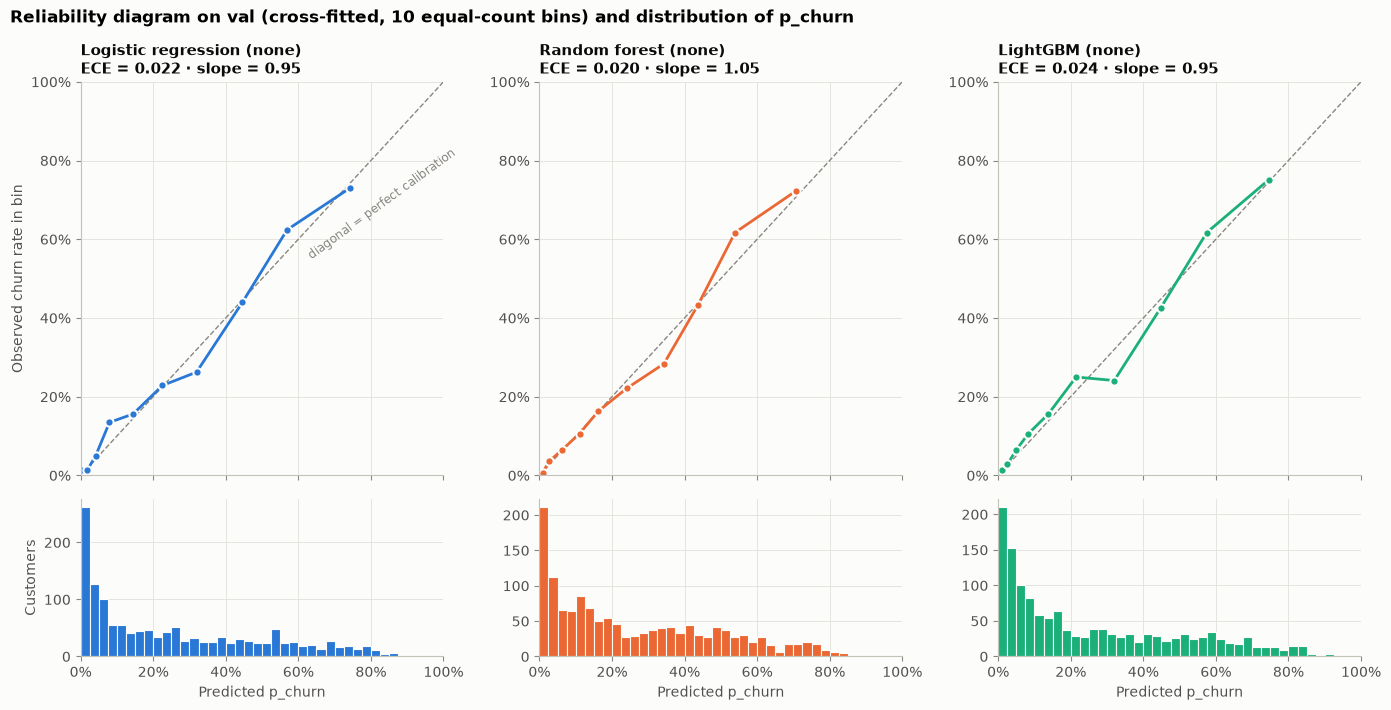

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
for j, n in enumerate(md.MODELS):
    ax, axh, c, p = axes[0, j], axes[1, j], MODEL_COLORS[n], p_final[n]
    t = md.reliability_table(p, y_val, n_bins)
    ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
    ax.plot(t["mean_p"], t["churn_rate"], color=c, lw=2, marker="o", ms=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    e = calib.loc[(LABELS[n], CAL_METHOD[n])]
    ax.set_title(f"{LABELS[n]} ({CAL_METHOD[n]})\nECE = {e['ece']:.3f} · slope = {e['calib_slope']:.2f}", loc="left")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    if j == 0:
        ax.set_ylabel("Observed churn rate in bin")
        ax.text(0.62, 0.55, "diagonal = perfect calibration", color=MUTED, fontsize=8.5, rotation=36)
    axh.hist(p, bins=np.linspace(0, 1, 41), color=c, edgecolor=SURFACE, linewidth=0.8)
    axh.set_xlabel("Predicted p_churn")
    axh.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    if j == 0:
        axh.set_ylabel("Customers")
fig.suptitle(f"Reliability diagram on val (cross-fitted, {n_bins} equal-count bins) and distribution of p_churn",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "m01_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

**Kết quả calibration**
- **Cả ba mô hình đã calibrate tốt ngay từ đầu:**
  - ECE từ 0.020 đến 0.024: trung bình `p` dự đoán lệch khoảng 2 điểm % so với tỉ lệ thực tế.
  - Slope 0.95 (LR, LightGBM) và 1.05 (RF).
  - `mean_p` từ 0.259 đến 0.264, so với tỉ lệ thực tế 0.265.
- **Platt không cải thiện.** Log loss gần như giữ nguyên (chênh ≤ 0.0003), dù slope về gần 1.00. Phần lệch còn lại nhỏ hơn nhiễu của val.
- **Isotonic làm kém đi rõ rệt**: log loss tăng 0.03–0.05. Mỗi lần fit chỉ có khoảng 300 khách churn, nên isotonic tạo các bậc thang quá khớp. Có nhóm bị gán `p` rất thấp, và bị phạt nặng khi khách trong nhóm đó churn.
- **Theo quy tắc chọn theo log loss, cả ba mô hình đều giữ phương án `none`** (không calibrate). `CalibratedModel` vẫn chứa calibrator `none`, để bước sau dùng chung một giao diện.
- **RF không bị dồn xác suất về giữa như lo ngại ban đầu.** Tuning theo log loss chọn lá lớn (`min_samples_leaf = 20`), làm xác suất mượt. Slope 1.05 cho thấy RF chỉ hơi "rụt rè".
- **Các điểm lệch xa nhất trên reliability diagram vẫn nằm trong mức nhiễu.** Nhóm `p` ≈ 30–35% có tỉ lệ thực tế 24–28%; nhóm `p` ≈ 55–58% có tỉ lệ thực tế khoảng 62%. Mỗi nhóm có khoảng 140 khách, nên sai số chuẩn của tỉ lệ thực tế là khoảng ±4 điểm %. Các lệch này nằm trong khoảng 2 sai số chuẩn.

### 4.2 Fit calibrator cuối cùng và lưu mô hình
- Calibrator fit trên **toàn bộ val** theo phương án đã chọn, ghép với pipeline đã fit trên train thành `CalibratedModel`.
- `val_predictions.csv` lưu `p` **cross-fitted** (`p_<model>`), là xác suất đánh giá trung thực trên val, để simulator chạy thử ở bước sau. `p_raw_<model>` là xác suất thô.

In [12]:
final_models = {}
for n in md.MODELS:
    cal = md.fit_calibrator(p_raw[n], y_val, CAL_METHOD[n])
    final_models[n] = md.CalibratedModel(searches[n].best_estimator_, cal, CAL_METHOD[n])
    joblib.dump(final_models[n], MODEL_DIR / f"{n}.joblib")

val_pred = pd.DataFrame({pp.ID_COL: val[pp.ID_COL], pp.TARGET: y_val,
                         **{f"p_raw_{n}": p_raw[n] for n in md.MODELS}, **{f"p_{n}": p_final[n] for n in md.MODELS}})
val_pred.to_csv(TAB_DIR / "val_predictions.csv", index=False)

checks = {}
for n in md.MODELS:
    reloaded = joblib.load(MODEL_DIR / f"{n}.joblib")
    expected = md.fit_calibrator(p_raw[n], y_val, CAL_METHOD[n]).predict(p_raw[n])
    checks[f"{n}.joblib reloads with identical val predictions"] = np.allclose(reloaded.predict_churn(val), expected)
display(pd.Series(checks, name="Passed").to_frame())
assert all(checks.values())
for n in md.MODELS:
    print(f"  {(MODEL_DIR / f'{n}.joblib').relative_to(ROOT)}  ({(MODEL_DIR / f'{n}.joblib').stat().st_size / 1024:,.0f} KB)")

,Passed
lr.joblib reloads with identical val predictions,True
rf.joblib reloads with identical val predictions,True
lgbm.joblib reloads with identical val predictions,True


  model_output/models/lr.joblib  (8 KB)
  model_output/models/rf.joblib  (6,454 KB)
  model_output/models/lgbm.joblib  (304 KB)


## 5. So sánh mô hình trên val

Dùng `p` cuối cùng của từng mô hình (cross-fitted theo phương án calibration đã chọn). Val chỉ có 1,409 khách (374 churn), nên mọi chỉ số đều kèm **CI 95% bootstrap** (1,000 lần lấy mẫu lại).

Chênh lệch giữa hai mô hình được tính bằng bootstrap **ghép cặp**: cùng một mẫu khách cho cả hai mô hình. Nếu CI của chênh lệch chứa 0 thì trên tập này chưa phân biệt được hai mô hình.

In [13]:
val_metrics = pd.DataFrame({LABELS[n]: md.evaluate(p_final[n], y_val, n_bins) for n in md.MODELS}).T
val_metrics.to_csv(TAB_DIR / "val_metrics.csv")
display(val_metrics.drop(columns="churn_rate").style.format("{:.4f}").format("{:.3f}", subset=["calib_slope"]))

ta = config["threshold_analysis"]
boot = md.bootstrap_compare({LABELS[n]: p_final[n] for n in md.MODELS}, y_val, ref=LABELS["lr"],
                            n_boot=ta["n_bootstrap"], seed=config["random_state"])
boot.to_csv(TAB_DIR / "val_bootstrap.csv", index=False)


def ci(est, lo, hi, signed=False):
    f = "{:+.3f}" if signed else "{:.3f}"
    return f"{f.format(est)}  [{f.format(lo)}, {f.format(hi)}]"


boot_view = pd.DataFrame({
    "estimate [95% CI]": boot.apply(lambda r: ci(r["estimate"], r["ci_low"], r["ci_high"]), axis=1),
    "difference vs LR [95% CI]": boot.apply(lambda r: ci(r["diff_vs_ref"], r["diff_ci_low"], r["diff_ci_high"], True)
                                               if r["model"] != LABELS["lr"] else "—", axis=1),
}).set_index(pd.MultiIndex.from_frame(boot[["metric", "model"]]))
display(boot_view)

,roc_auc,pr_auc,log_loss,brier,ece,calib_slope,mean_p
Logistic regression,0.8415,0.6539,0.4216,0.1361,0.0220,0.946,0.2595
Random forest,0.8375,0.6388,0.4273,0.1381,0.0195,1.049,0.2638
LightGBM,0.8375,0.6471,0.4251,0.1373,0.0244,0.949,0.2613


,,estimate [95% CI],difference vs LR [95% CI]
metric,model,,
roc_auc,Logistic regression,"0.841 [0.819, 0.862]",—
pr_auc,Logistic regression,"0.654 [0.602, 0.705]",—
log_loss,Logistic regression,"0.422 [0.393, 0.452]",—
brier,Logistic regression,"0.136 [0.126, 0.147]",—
roc_auc,Random forest,"0.837 [0.814, 0.859]","-0.004 [-0.010, +0.002]"
pr_auc,Random forest,"0.639 [0.586, 0.696]","-0.014 [-0.032, +0.005]"
log_loss,Random forest,"0.427 [0.400, 0.456]","+0.006 [-0.001, +0.013]"
brier,Random forest,"0.138 [0.128, 0.148]","+0.002 [-0.000, +0.004]"
roc_auc,LightGBM,"0.838 [0.814, 0.860]","-0.004 [-0.009, +0.000]"


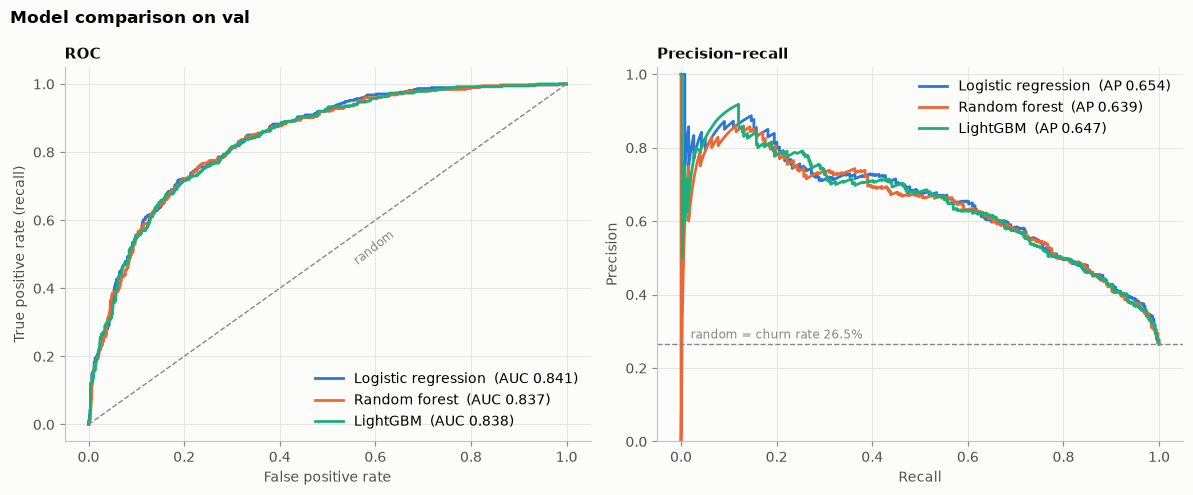

In [14]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
for n in md.MODELS:
    c, p, m = MODEL_COLORS[n], p_final[n], val_metrics.loc[LABELS[n]]
    fpr, tpr, _ = roc_curve(y_val, p)
    ax_roc.plot(fpr, tpr, color=c, lw=2, label=f"{LABELS[n]}  (AUC {m['roc_auc']:.3f})")
    prec, rec, _ = precision_recall_curve(y_val, p)
    ax_pr.plot(rec, prec, color=c, lw=2, label=f"{LABELS[n]}  (AP {m['pr_auc']:.3f})")
ax_roc.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
ax_roc.text(0.55, 0.47, "random", color=MUTED, fontsize=8.5, rotation=38)
ax_pr.axhline(y_val.mean(), color=MUTED, ls="--", lw=1)
ax_pr.text(0.02, y_val.mean() + 0.015, f"random = churn rate {y_val.mean():.1%}", color=MUTED, fontsize=8.5)
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate (recall)")
ax_pr.set(xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
ax_roc.set_title("ROC", loc="left")
ax_pr.set_title("Precision–recall", loc="left")
for ax in (ax_roc, ax_pr):
    ax.legend(loc="lower right" if ax is ax_roc else "upper right")
fig.suptitle("Model comparison on val", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "m02_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

**Kết quả so sánh trên val**

| | LR | RF | LightGBM |
|---|---|---|---|
| ROC-AUC | **0.841** | 0.837 | 0.838 |
| PR-AUC | **0.654** | 0.639 | 0.647 |
| Log loss | **0.422** | 0.427 | 0.425 |
| Brier | **0.136** | 0.138 | 0.137 |

- **LR nhỉnh hơn ở mọi chỉ số, nhưng mọi CI của chênh lệch đều chứa 0.** Trên 1,409 khách của val, chưa phân biệt được ba mô hình. RF gần mức "kém hơn có ý nghĩa" nhất: log loss +0.006 [−0.001, +0.013], Brier +0.002 [−0.000, +0.004].
- **CI của từng chỉ số rất rộng so với chênh lệch giữa các mô hình.** CI của PR-AUC rộng khoảng ±0.05, trong khi chênh lệch giữa các mô hình ≤ 0.015. Chọn mô hình theo AUC ở đây là chọn theo nhiễu.
- **Val thấp hơn CV một chút**, ví dụ ROC-AUC của LR là 0.841 so với 0.852. Giá trị của CV vẫn nằm trong CI của val [0.819, 0.862], và cả ba mô hình giảm như nhau. Đây là biến động mẫu của val, không phải dấu hiệu overfit riêng của mô hình nào.

## 6. Phân tích ngưỡng

Có hai cách biến `p_churn` thành quyết định "liên hệ / không liên hệ":
1. **Ngưỡng xác suất:** liên hệ mọi khách có `p ≥ t`. Số khách được liên hệ thay đổi theo `t`.
2. **Ngưỡng theo năng lực (top-K):** ngân sách cố định cho phép liên hệ K khách, nên ngưỡng là `p` của khách thứ K. Đây là dạng mà bài toán ngân sách cần.

Ngưỡng 0.5 và ngưỡng tối ưu F1 chỉ là **mốc kỹ thuật**: cả hai coi bỏ sót một khách churn và liên hệ nhầm một khách đều tốn như nhau. Ngưỡng ra quyết định thật phụ thuộc vào giá trị khách, chi phí ưu đãi và tỉ lệ cứu được. Ngưỡng đó sẽ được đặt ở bước simulator (hoà vốn khi `p × save_rate × V = cost`).

### 6.1 Ngưỡng xác suất

In [15]:
f1_thr = {n: md.best_f1_threshold(p_final[n], y_val) for n in md.MODELS}
thr_table = pd.concat({LABELS[n]: md.threshold_table(p_final[n], y_val, sorted({*ta["thresholds"], f1_thr[n]}))
                       .assign(**{"note": lambda d, t=f1_thr[n]: np.where(np.isclose(d["threshold"], t), "best F1", "")})
                       for n in md.MODELS}, names=["model", None]).droplevel(1).set_index("threshold", append=True)
thr_table.to_csv(TAB_DIR / "threshold_table.csv")
display(thr_table.style.format({"flagged_share": "{:.1%}", "precision": "{:.1%}", "recall": "{:.1%}", "f1": "{:.3f}"})
        .format_index("{:.3f}", level=1))

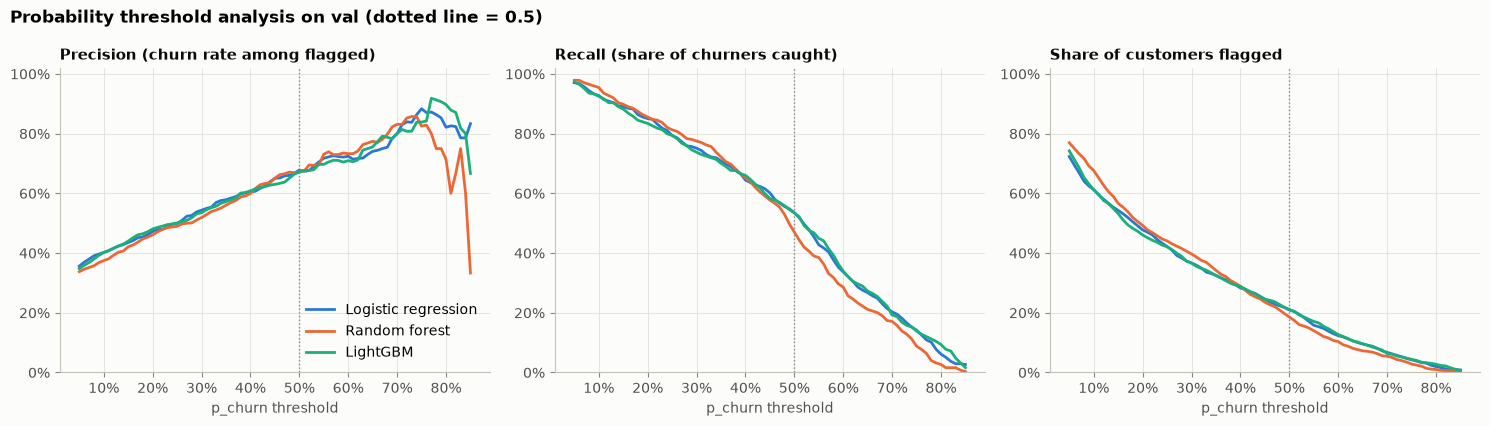

In [16]:
grid = np.linspace(0.05, 0.85, 81)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharex=True)
for n in md.MODELS:
    t = md.threshold_table(p_final[n], y_val, grid)
    for ax, col in zip(axes, ["precision", "recall", "flagged_share"]):
        ax.plot(t["threshold"], t[col], color=MODEL_COLORS[n], lw=2, label=LABELS[n])
for ax, title in zip(axes, ["Precision (churn rate among flagged)", "Recall (share of churners caught)",
                            "Share of customers flagged"]):
    ax.axvline(0.5, color=MUTED, ls=":", lw=1)
    ax.set_title(title, loc="left")
    ax.set_xlabel("p_churn threshold")
    ax.set_ylim(0, 1.02)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].legend(loc="lower right")
fig.suptitle("Probability threshold analysis on val (dotted line = 0.5)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "m03_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Ngưỡng theo năng lực liên hệ (top-K)
Xếp khách theo `p` giảm dần, liên hệ K% khách đầu tiên.
- `precision`: tỉ lệ churn thực tế trong nhóm được liên hệ.
- `mean_p`: tỉ lệ churn mà mô hình dự đoán cho nhóm đó.
- `lift`: precision chia cho tỉ lệ churn chung.

`mean_p` gần `precision` nghĩa là xác suất đáng tin **ngay trong nhóm sẽ nhận ưu đãi**. Đây chính là phần xác suất mà công thức EV sử dụng.

In [17]:
topk = pd.concat({LABELS[n]: md.topk_table(p_final[n], y_val, ta["top_k_shares"]) for n in md.MODELS},
                 names=["model", None]).droplevel(1).set_index("share", append=True)
topk.to_csv(TAB_DIR / "topk_table.csv")
display(topk.style.format({"k": "{:,}", "cutoff_p": "{:.3f}", "mean_p": "{:.1%}", "precision": "{:.1%}",
                           "recall": "{:.1%}", "lift": "{:.2f}×"}).format_index("{:.0%}", level=1))

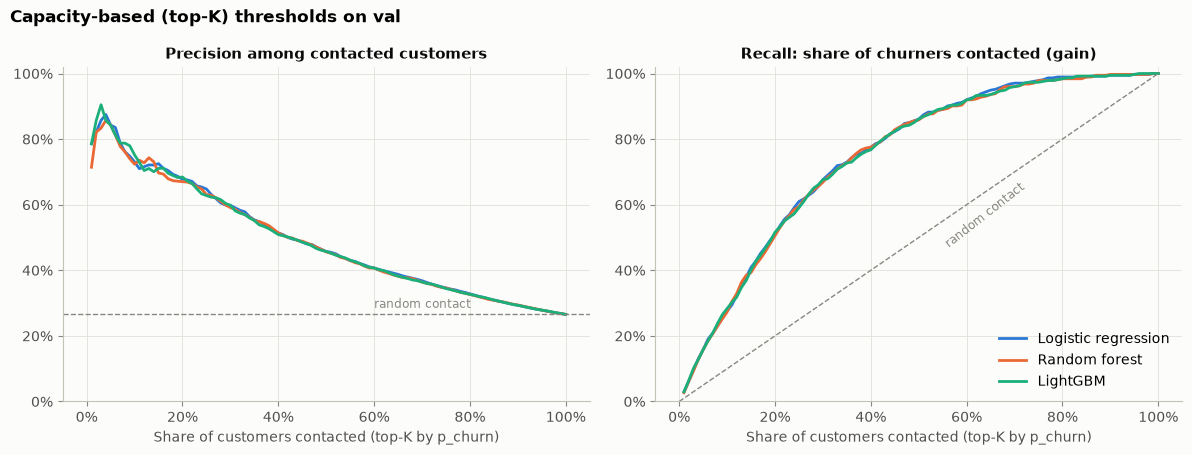

In [18]:
shares = np.linspace(0.01, 1, 100)
fig, (ax_p, ax_r) = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for n in md.MODELS:
    t = md.topk_table(p_final[n], y_val, shares)
    ax_p.plot(t["share"], t["precision"], color=MODEL_COLORS[n], lw=2, label=LABELS[n])
    ax_r.plot(t["share"], t["recall"], color=MODEL_COLORS[n], lw=2, label=LABELS[n])
ax_p.axhline(y_val.mean(), color=MUTED, ls="--", lw=1)
ax_p.text(0.6, y_val.mean() + 0.02, "random contact", color=MUTED, fontsize=8.5)
ax_r.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
ax_r.text(0.55, 0.47, "random contact", color=MUTED, fontsize=8.5, rotation=38)
ax_p.set(title="Precision among contacted customers", ylim=(0, 1.02))
ax_r.set(title="Recall: share of churners contacted (gain)", ylim=(0, 1.02))
for ax in (ax_p, ax_r):
    ax.set_xlabel("Share of customers contacted (top-K by p_churn)")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax_r.legend(loc="lower right")
fig.suptitle("Capacity-based (top-K) thresholds on val", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "m04_topk.png", dpi=150, bbox_inches="tight")
plt.show()

**Kết quả phân tích ngưỡng**
- **Đường precision / recall của ba mô hình gần như trùng nhau** ở mọi ngưỡng và mọi mức K. Khác biệt nhỏ về thứ hạng không thành khác biệt về quyết định.
- **Ngưỡng 0.5 bỏ sót gần nửa số khách churn.** Ở ngưỡng này, 19–21% khách bị gắn cờ, precision 67–68%, nhưng recall chỉ 47–53%.
- **Ngưỡng tối ưu F1 thấp hơn nhiều:** 0.35 (LR), 0.36 (RF), 0.38 (LightGBM). Ở đó 30–33% khách bị gắn cờ, precision 57–60%, recall 68–72%. Với lớp churn chỉ chiếm 26.5%, ngưỡng 0.5 không có gì đặc biệt.
- **Top-K của LR:**

  | Liên hệ | Precision | Bắt được (recall) | Lift |
  |---|---|---|---|
  | 10% khách | 73% | 28% | 2.75× |
  | 20% khách | 68% | 51% | 2.55× |
  | 30% khách | 60% | 68% | 2.25× |

  Precision giảm đều khi K tăng, vì mỗi khách thêm vào danh sách có xác suất churn thấp hơn khách trước. Ngân sách sẽ quyết định điểm dừng trên đánh đổi này.
- **Xác suất đáng tin ngay trong nhóm được liên hệ.** Với LR, `mean_p` của top 10% / 20% / 30% là 74% / 66% / 59%, so với tỉ lệ thực tế 73% / 68% / 60%: lệch ≤ 3 điểm %. Ở top 5%, mô hình hơi **dự đoán thấp** (80% so với 84%), nên EV tính từ `p` sẽ hơi thận trọng chứ không bị thổi phồng.
- **Bước tiếp theo: thay F1 bằng ngưỡng kinh tế.** Với chi phí ưu đãi `c`, tỉ lệ cứu `s` và giá trị khách `V`, khách đáng liên hệ khi `p > c / (s · V)`. Ngưỡng này **khác nhau cho từng khách**, nên thứ tự liên hệ sẽ khác với thứ tự theo `p`.

## 7. Tổng kết

### 7.1 Kết quả chính

| | Logistic regression | Random forest | LightGBM |
|---|---|---|---|
| Feature (sau encode) | 26 cột: bộ gốc + `log_TotalCharges` | 33 cột, dạng gốc | 33 cột, dạng gốc |
| Tham số tốt nhất | `C = 1` (L2) | 500 cây, `max_features = sqrt`, `min_samples_leaf = 20` | 800 stump, `min_child_samples = 200` |
| CV log loss (train) | **0.408** | 0.414 | 0.409 |
| Val ROC-AUC [CI 95%] | **0.841** [0.819, 0.862] | 0.837 [0.814, 0.859] | 0.838 [0.814, 0.860] |
| Val PR-AUC [CI 95%] | **0.654** [0.602, 0.705] | 0.639 [0.586, 0.696] | 0.647 [0.594, 0.702] |
| Val log loss / Brier | **0.422 / 0.136** | 0.427 / 0.138 | 0.425 / 0.137 |
| ECE / calibration slope | 0.022 / 0.95 | 0.020 / 1.05 | 0.024 / 0.95 |
| Calibration chọn | none | none | none |
| Top 20%: precision / recall | 67.7% / 51.1% | 67.0% / 50.5% | 68.4% / 51.6% |

1. **Ba mô hình ngang nhau trong mức nhiễu.** LR nhỉnh hơn ở mọi chỉ số, cả trên CV lẫn val, nhưng không có chênh lệch nào có ý nghĩa thống kê.
2. **Xác suất dùng được trực tiếp cho EV.** Cả ba đã calibrate tốt; Platt không cải thiện, isotonic làm kém đi. Xác suất đúng cả trong nhóm sẽ được liên hệ.
3. **Không có tương tác ẩn đáng kể mà LR bỏ lỡ.** LightGBM tự chọn mô hình cộng tính (stump).
4. **Đề xuất, chưa chốt: LR làm mô hình chính cho simulator; RF và LightGBM làm challenger.** Lý do: LR tốt nhất hoặc ngang bằng ở mọi chỉ số, diễn giải được (là nền cho churn scorecard) và nhỏ (8 KB). Quy tắc chốt giữ nguyên như kế hoạch: so sánh giá trị ròng EV ở mức ngân sách tham chiếu trên val; nếu chênh lệch nằm trong CI bootstrap thì chọn LR.

### 7.2 Giới hạn cần ghi vào model card
- **Val nhỏ:** 1,409 khách, 374 churn, nên CI rộng. Chênh lệch dưới khoảng 0.02 AUC không phân biệt được.
- **Không có temporal holdout:** dữ liệu là một snapshot hư cấu. Mô hình chưa được kiểm tra trên dữ liệu ở kỳ sau, và có giới hạn khi áp dụng cho nhà mạng thật (external validity).
- **Hệ số LR** có regularize và có cộng tuyến, nên chỉ dùng để kiểm tra tính hợp lý, không đọc như tác động nhân quả.
- **`SeniorCitizen` có trong cả ba mô hình.** Ở bước simulator cần kiểm tra fairness: tỉ lệ được liên hệ theo nhóm tuổi.
- **Tập test chưa được dùng.**

### 7.3 Đầu ra

| File | Nội dung |
|---|---|
| `model_output/models/{lr,rf,lgbm}.joblib` | `CalibratedModel`: pipeline fit trên train + calibrator fit trên val |
| `model_output/tables/val_predictions.csv` | `customerID`, `y`, `p_raw_*`, `p_*` (cross-fitted) trên val |
| `model_output/tables/lr_feature_selection.csv`, `best_params.csv`, `cv_results.csv`, `lr_coefficients.csv` | Chọn feature, tuning, hệ số LR |
| `model_output/tables/calibration_methods.csv`, `val_metrics.csv`, `val_bootstrap.csv` | Calibration và so sánh mô hình |
| `model_output/tables/threshold_table.csv`, `topk_table.csv` | Phân tích ngưỡng |
| `model_output/figures/m01_calibration.png` … `m04_topk.png` | Biểu đồ |

### 7.4 Cách dùng ở bước tiếp theo
```python
import joblib
from src import modeling as md          # `src` must be on sys.path so joblib can load CalibratedModel

model = joblib.load(ROOT / "model_output" / "models" / "lr.joblib")
p = model.predict_churn(df)             # df has the columns of telco_clean.csv; returns p_churn
```

### 7.5 Bước tiếp theo
1. **Simulator:** value proxy, công thức EV, so sánh chính sách (EV, chỉ theo rủi ro, chỉ theo giá trị, quy tắc EDA, ngẫu nhiên) và phân tích độ nhạy theo `save_rate` và `offer_cost`.
2. **Chốt mô hình chính** theo EV trên val, rồi đánh giá test **một lần**.
3. *(Stretch)* SHAP cho LightGBM.